In [1]:
import ast
import os
import optuna
import ipynbname
import pandas as pd
import numpy as np
from optuna.exceptions import TrialPruned
from Functions.AutoCloud_V5_1 import *
from Functions.Utils import *
from Functions.Graphs import *
from Functions.TedaGraphs import *

from Functions.Utils_OPT_R2 import *

FileName = ipynbname.name()

# Configuração do experimento
FEEDBACK = 'symmetric'      # 'symmetric' (gradiente no passo atual) ou 'random' (ablação: RFLO + DFA)
WTAG, WTAP = False, False   # configuração principal: soma ponderada dos grânulos (eq. 36)
EOL = 0.3                   # limiar de fim de vida (EoL) do HI

def RunTag(feedback=None, wtaG=None, wtaP=None):
    # Uma pasta de resultados por configuração (feedback, wtaG, wtaP)
    feedback = FEEDBACK if feedback is None else feedback
    wtaG = WTAG if wtaG is None else wtaG
    wtaP = WTAP if wtaP is None else wtaP
    return f'{FileName}_{feedback}_G{int(wtaG)}P{int(wtaP)}'

def RefEoL(sig, eol, nI, mO, mode):
    '''
    Referência da RUL real baseada no limiar de EoL (eq. 12): RUL_real = iEoL - k_dado.
    O AutoCloud calcula rulR = ref - k, com k = j + 2 na iteração j, e o PrepareData
    alinha a iteração j à amostra k_dado = k0 + j. Logo ref = iEoL - k0 + 2.
    Retorna ref e J, o número de iterações com RUL real >= 1.
    '''
    sig = np.asarray(sig, dtype=float)
    if not np.any(sig <= eol): raise ValueError('O HI nunca atinge o limiar de EoL.')
    iEoL = int(np.argmax(sig <= eol))
    k0 = (max(nI, 1, mO) if mode in ('ahead', 1) else max(nI, 1)) - 1
    return iEoL - k0 + 2, iEoL - k0

def nOMax(sig, eol):
    '''
    Maior nO (modo 'ahead') para o qual o fluxo do PrepareData alcança a última amostra antes do EoL.
    A última janela fica em k = K - nO - 2 (o PrepareData descarta a última); exigir k >= iEoL - 1
    dá nO <= K - iEoL - 1, independente de nI e mO. No modo 'past' o fluxo sempre alcança o EoL.
    '''
    sig = np.asarray(sig, dtype=float)
    return len(sig) - int(np.argmax(sig <= eol)) - 1

out_path = os.path.join('Optimization', RunTag(), 'multi', 'Optimization.csv')
dfs = [pd.read_csv(out_path)] if os.path.exists(out_path) else []
RS = pd.read_excel(r'Dataset\RS.xlsx')
HI = pd.read_excel(r'Dataset\HI.xlsx')
sig = HI['PC1'].values

c:\Users\Usuario\Desktop\Python\Batteries_Prognostics\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\Usuario\Desktop\Python\Batteries_Prognostics\Functions\AutoCloud_V5_1.py:166: RuntimeWarning: invalid value encountered in scalar divide
  spVal = max(0, 1 - (rU-rL)/Range )


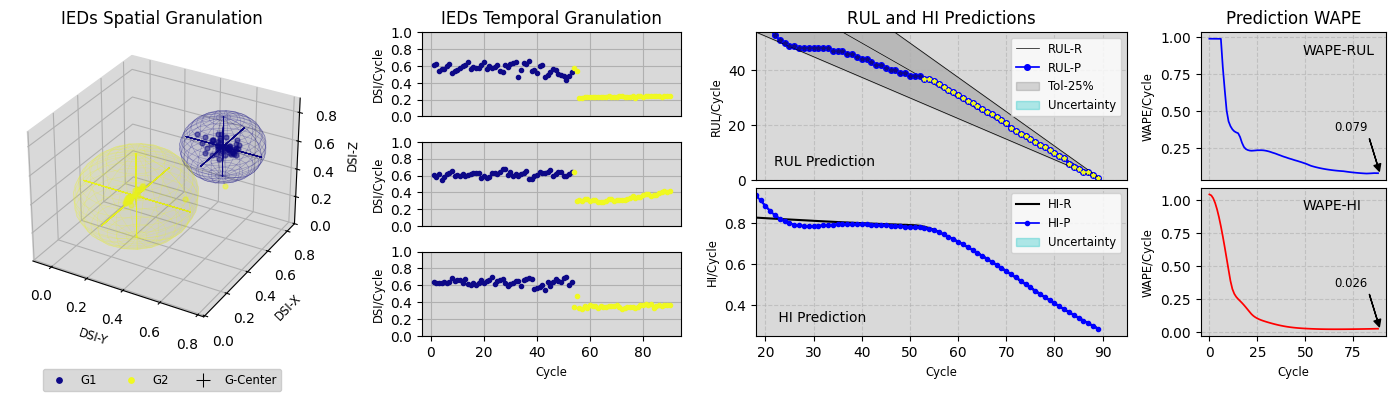

In [2]:
# Teste rápido (smoke test): parâmetros ajustados no R07 para a regra antiga (DRTLO_GD_R2).
# Não são válidos para o eRNN_GD_R2; os parâmetros finais devem vir de uma nova busca (Optimize).
params = [3.0,24,"[36, 68, 28, 52, 33, 25]",3,0,1,2,9,5,0,0]

m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
               tau=τ,rho=0.5,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO) 


for j,_ in enumerate(X[:J]):
    teda.run(X[j])
    teda.RUL_Prediction(Y[j],mode='single',lim=len(sig)-nI+1,show=False)
    teda.WAPE_HI2(Y[j],Z[j])
    teda.Adapt(Y[j],Z[j])
    teda.RUL_Granularity()

#teda.c = np.append(teda.c,teda.gm)  
PlotDSI_3D_PLT(teda)


In [3]:
len(teda.wape_RUL_hist)

90

In [4]:
PlotSeriesPLY(ySeries=[teda.erulR_hist, teda.erulP_hist],names=['wape_rul','wape_Pred',])

In [18]:
rhos = np.linspace(1e-9,100, 40)
m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

sp,cov = np.array([]),np.array([])
for rho in rhos:

    teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
                tau=τ,rho=rho,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO) 


    for j,_ in enumerate(X[:J]):
        teda.run(X[j])
        teda.RUL_Prediction(Y[j],mode='single',lim=len(sig)-nI+1,show=False)
        teda.WAPE_HI2(Y[j],Z[j])
        teda.Adapt(Y[j],Z[j])
        teda.RUL_Granularity()
    sp = np.append(sp,teda.sp)
    cov = np.append(cov,teda.cov)


In [19]:
PlotSeriesPLY(xSeries=[rhos,rhos,rhos],ySeries=[cov,sp,cov*sp],names=['cov','sp','V'])

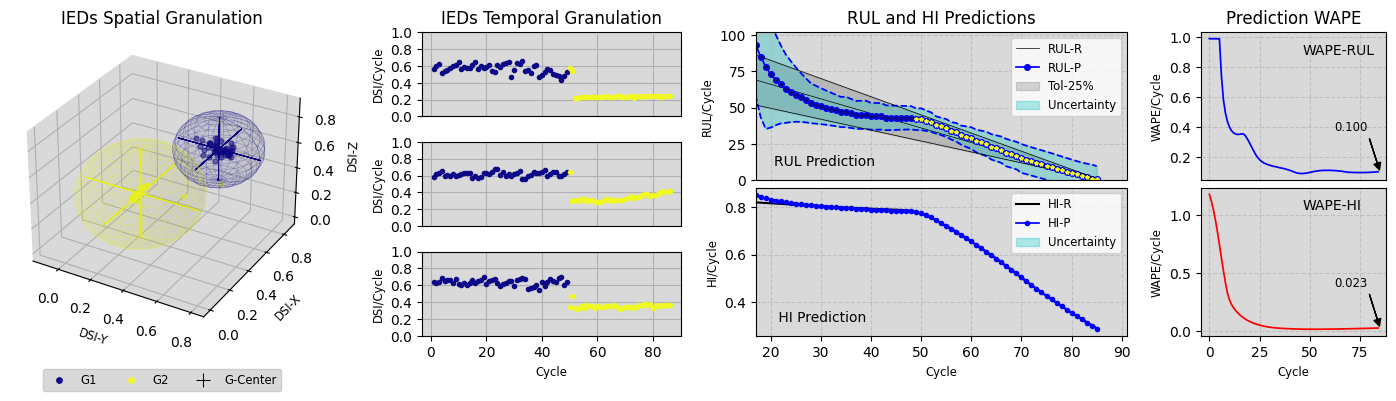

In [20]:
# Teste rápido (smoke test): parâmetros ajustados no R07 para a regra antiga (DRTLO_GD_R2).
# Não são válidos para o eRNN_GD_R2; os parâmetros finais devem vir de uma nova busca (Optimize).
params = [3.5,28,[70],8,0,1,2,5,19,1,0]

m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
               tau=τ,rho=84,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO) 


for j,_ in enumerate(X[:J]):
    teda.run(X[j])
    teda.RUL_Prediction(Y[j],mode='single',lim=len(sig)-nI+1,show=False)
    teda.WAPE_HI2(Y[j],Z[j])
    teda.Adapt(Y[j],Z[j])
    teda.RUL_Granularity()

#teda.c = np.append(teda.c,teda.gm)  
PlotDSI_3D_PLT(teda)


In [11]:
(teda.wape_RUL)

np.float64(0.07859352500810442)

In [5]:
PlotSeriesPLY(ySeries=[teda.wape_RUL_hist, teda.erulP_hist],names=['wape_rul','wape_Pred',])

In [6]:
teda.rulP - teda.rulL

array([0.        , 0.494444  , 0.49442157, 0.49439729, 0.4943715 ,
       0.49434432, 0.49431582, 0.494286  , 0.39231274, 0.21658502,
       0.15319983, 0.17122235, 0.1867492 , 0.18715799, 0.18533875,
       0.18723458, 0.23443119, 0.26976005, 0.26352451, 0.22032411,
       0.18163375, 0.15710083, 0.14209163, 0.13200176, 0.12634029,
       0.12251931, 0.12128704, 0.11895776, 0.11861523, 0.11829734,
       0.11791644, 0.1174227 , 0.11678669, 0.11599056, 0.11342255,
       0.11251118, 0.11145093, 0.1085194 , 0.10733866, 0.10421299,
       0.1010902 , 0.09991991, 0.09666853, 0.09345697, 0.09241343,
       0.08910723, 0.08587739, 0.08502643, 0.08171377, 0.08087535,
       0.07742871, 0.07656454, 0.0755062 , 0.07158604, 0.07042224,
       0.06637317, 0.06252004, 0.05894637, 0.05572109, 0.05288707,
       0.05045777, 0.04842135, 0.04674875, 0.04540236, 0.04434303,
       0.04353469, 0.04294689, 0.04255576, 0.04234399, 0.04230045,
       0.04241946, 0.04237593, 0.04317274, 0.04387538, 0.04456

In [4]:
rho = 0.9
Range = rho*teda.erulP_hist
rulR = teda.rulR
rulP = teda.rulP
rulL = teda.rulL 
rulU  = teda.rulU 
PlotSeriesPLY(ySeries=[rulR,rulP,rulL,rulU],names=['rulR','rulP','rulL','rulU'])

In [ ]:
print(xxx)

NameError: name 'xxx' is not defined